# Data processing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns

In [2]:
URL = "https://raw.githubusercontent.com/akaykemal/Stellar-Classification-Dataset---SDSS17/main/star_classification.csv"

In [3]:
df = pd.read_csv(URL).copy()

In [4]:
df.shape

(100000, 18)

In [5]:
df.columns

Index(['obj_ID', 'alpha', 'delta', 'u', 'g', 'r', 'i', 'z', 'run_ID',
       'rerun_ID', 'cam_col', 'field_ID', 'spec_obj_ID', 'class', 'redshift',
       'plate', 'MJD', 'fiber_ID'],
      dtype='str')

In [6]:
print(f"all columns: {df.columns.tolist()}")
df.info()

all columns: ['obj_ID', 'alpha', 'delta', 'u', 'g', 'r', 'i', 'z', 'run_ID', 'rerun_ID', 'cam_col', 'field_ID', 'spec_obj_ID', 'class', 'redshift', 'plate', 'MJD', 'fiber_ID']
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   obj_ID       100000 non-null  float64
 1   alpha        100000 non-null  float64
 2   delta        100000 non-null  float64
 3   u            100000 non-null  float64
 4   g            100000 non-null  float64
 5   r            100000 non-null  float64
 6   i            100000 non-null  float64
 7   z            100000 non-null  float64
 8   run_ID       100000 non-null  int64  
 9   rerun_ID     100000 non-null  int64  
 10  cam_col      100000 non-null  int64  
 11  field_ID     100000 non-null  int64  
 12  spec_obj_ID  100000 non-null  float64
 13  class        100000 non-null  str    
 14  redshift     100000 non-null  fl

# EDA(Exploratory Data Analysis)

In [32]:
mag = ['u', 'g', 'r', 'i', 'z']
df = df[(df[mag] > -9000).all(axis=1)].reset_index(drop=True)

In [7]:
df.head()

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842


In [33]:
df.describe().round(2)

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,redshift,plate,MJD,fiber_ID
count,9.999900e+04,99999.00,99999.00,99999.00,99999.00,99999.00,99999.00,99999.00,99999.00,99999.0,99999.00,99999.00,9.999900e+04,99999.00,99999.00,99999.00,99999.00
mean,1.237665e+18,177.63,24.14,22.08,20.63,19.65,19.08,18.77,4481.40,301.0,3.51,186.13,5.783903e+18,0.58,5137.03,55588.65,449.32
std,8.438450e+12,96.50,19.64,2.25,2.04,1.85,1.76,1.77,1964.74,0.0,1.59,149.01,3.324026e+18,0.73,2952.31,1808.49,272.50
min,1.237646e+18,0.01,-18.79,11.00,10.50,9.82,9.47,9.61,109.00,301.0,1.00,11.00,2.995191e+17,-0.01,266.00,51608.00,1.00
25%,1.237659e+18,127.52,5.15,20.35,18.97,18.14,17.73,17.46,3187.00,301.0,2.00,82.00,2.844137e+18,0.05,2526.00,54234.00,221.00
50%,1.237663e+18,180.90,23.65,22.18,21.10,20.13,19.41,19.00,4188.00,301.0,4.00,146.00,5.614896e+18,0.42,4987.00,55869.00,433.00
75%,1.237668e+18,233.90,39.90,23.69,22.12,21.04,20.40,19.92,5326.00,301.0,5.00,241.00,8.332365e+18,0.70,7400.50,56777.00,645.00
max,1.237681e+18,360.00,83.00,32.78,31.60,29.57,32.14,29.38,8162.00,301.0,6.00,989.00,1.412694e+19,7.01,12547.00,58932.00,1000.00


In [34]:
df.isnull().sum()

obj_ID         0
alpha          0
delta          0
u              0
g              0
r              0
i              0
z              0
run_ID         0
rerun_ID       0
cam_col        0
field_ID       0
spec_obj_ID    0
class          0
redshift       0
plate          0
MJD            0
fiber_ID       0
dtype: int64

## Class distribution(target variable Y)

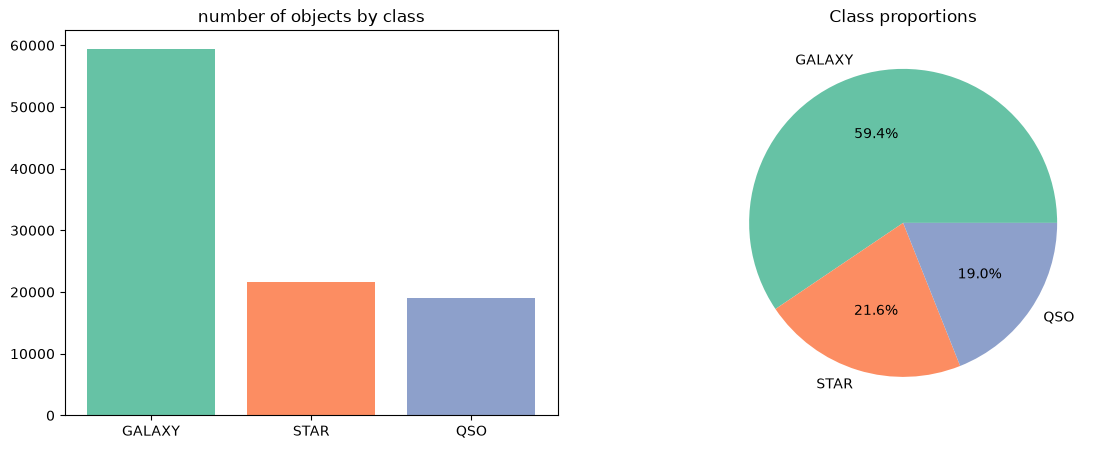

In [35]:
target_col = "class"
class_counts = df[target_col].value_counts()
class_prop = df[target_col].value_counts(normalize=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].set_title("number of objects by class")
axes[0].bar(x = class_counts.index, height = class_counts.values, color=sns.color_palette("Set2"))

axes[1].set_title("Class proportions")
axes[1].pie(class_prop, labels=class_prop.index, autopct='%1.1f%%', colors=sns.color_palette("Set2"))

## Feature distribution $x_1, x_2, ..., x_d$

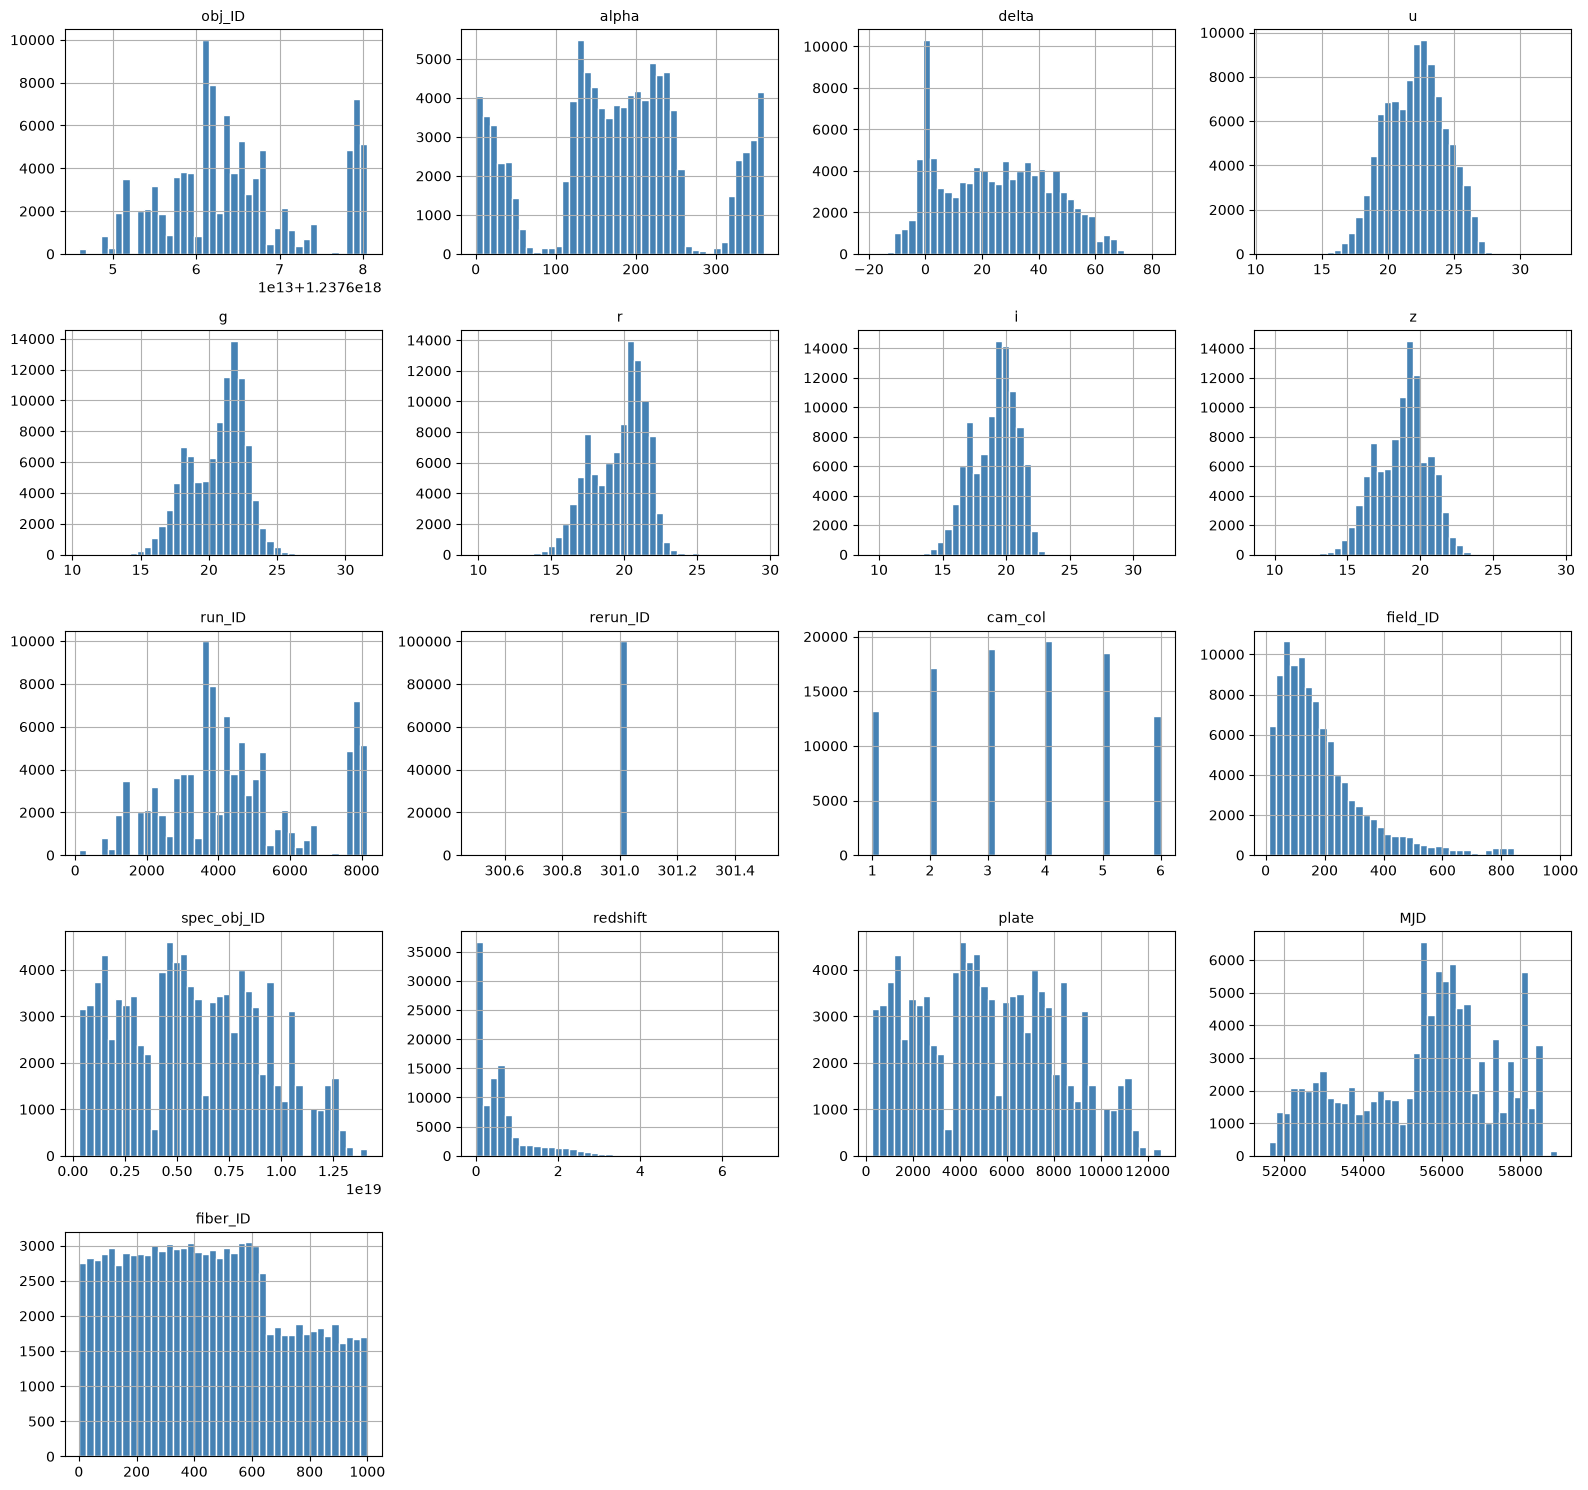

In [36]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

#number of columns
n_cols = len(numeric_cols) 
n_rows = (n_cols + 3) // 4 

fig, axes = plt.subplots(n_rows, 4, figsize=(16, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    df[col].hist(bins=40, ax=axes[i], color='steelblue', edgecolor='white')
    axes[i].set_title(col, fontsize=10)

for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

## Correlation matrix

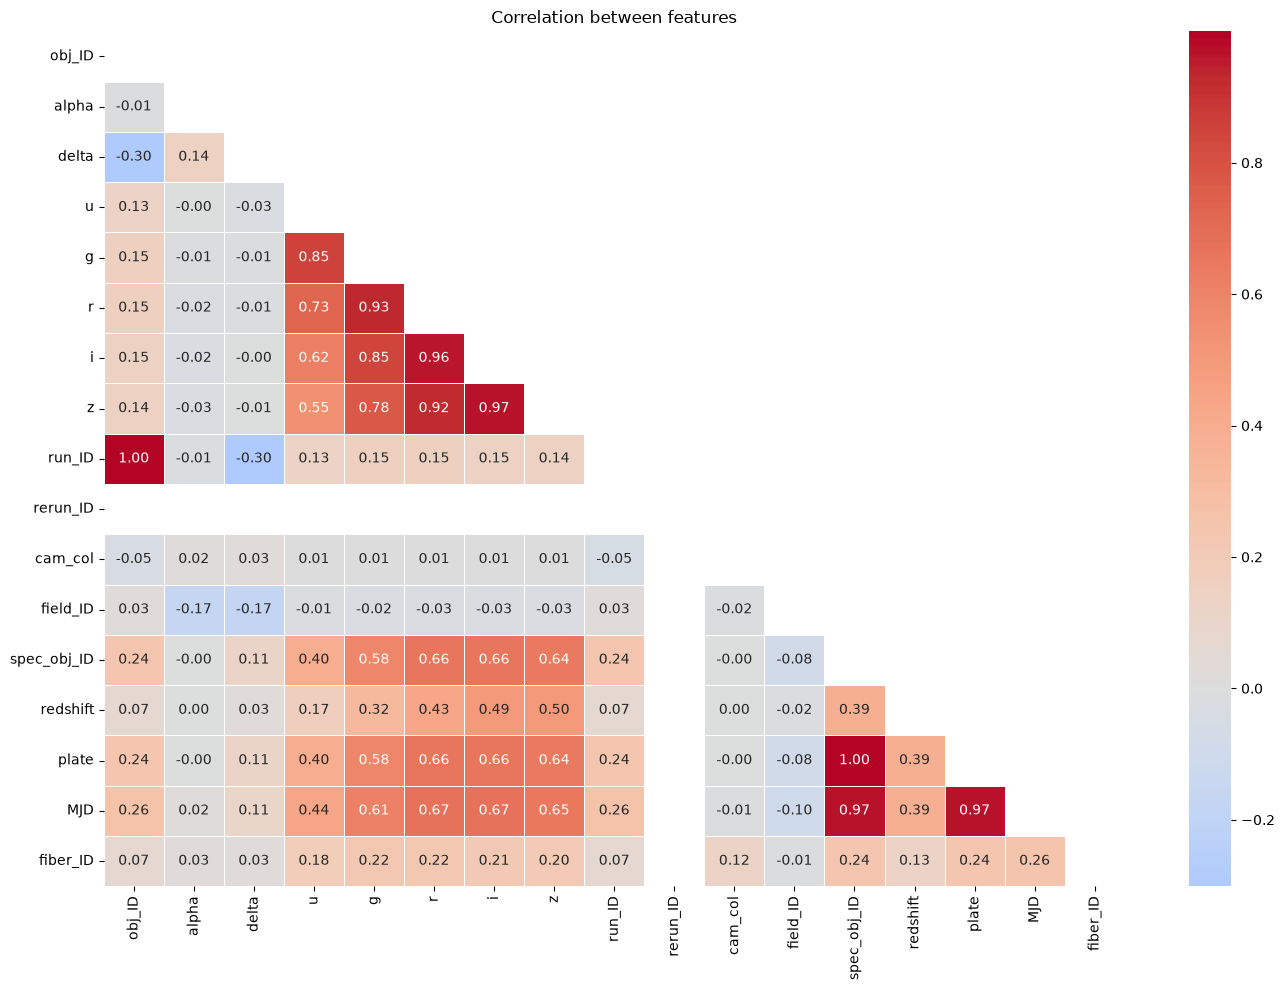

In [39]:
plt.figure(figsize=(14,10))
corr = df[numeric_cols].corr() 
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title("Correlation between features")
plt.tight_layout()
plt.show()

## Boxplot of features by class

/tmp/ipykernel_42913/262916503.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=target_col, y=col, ax=ax, palette='Set2')
/tmp/ipykernel_42913/262916503.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=target_col, y=col, ax=ax, palette='Set2')
/tmp/ipykernel_42913/262916503.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=target_col, y=col, ax=ax, palette='Set2')
/tmp/ipykernel_42913/262916503.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.

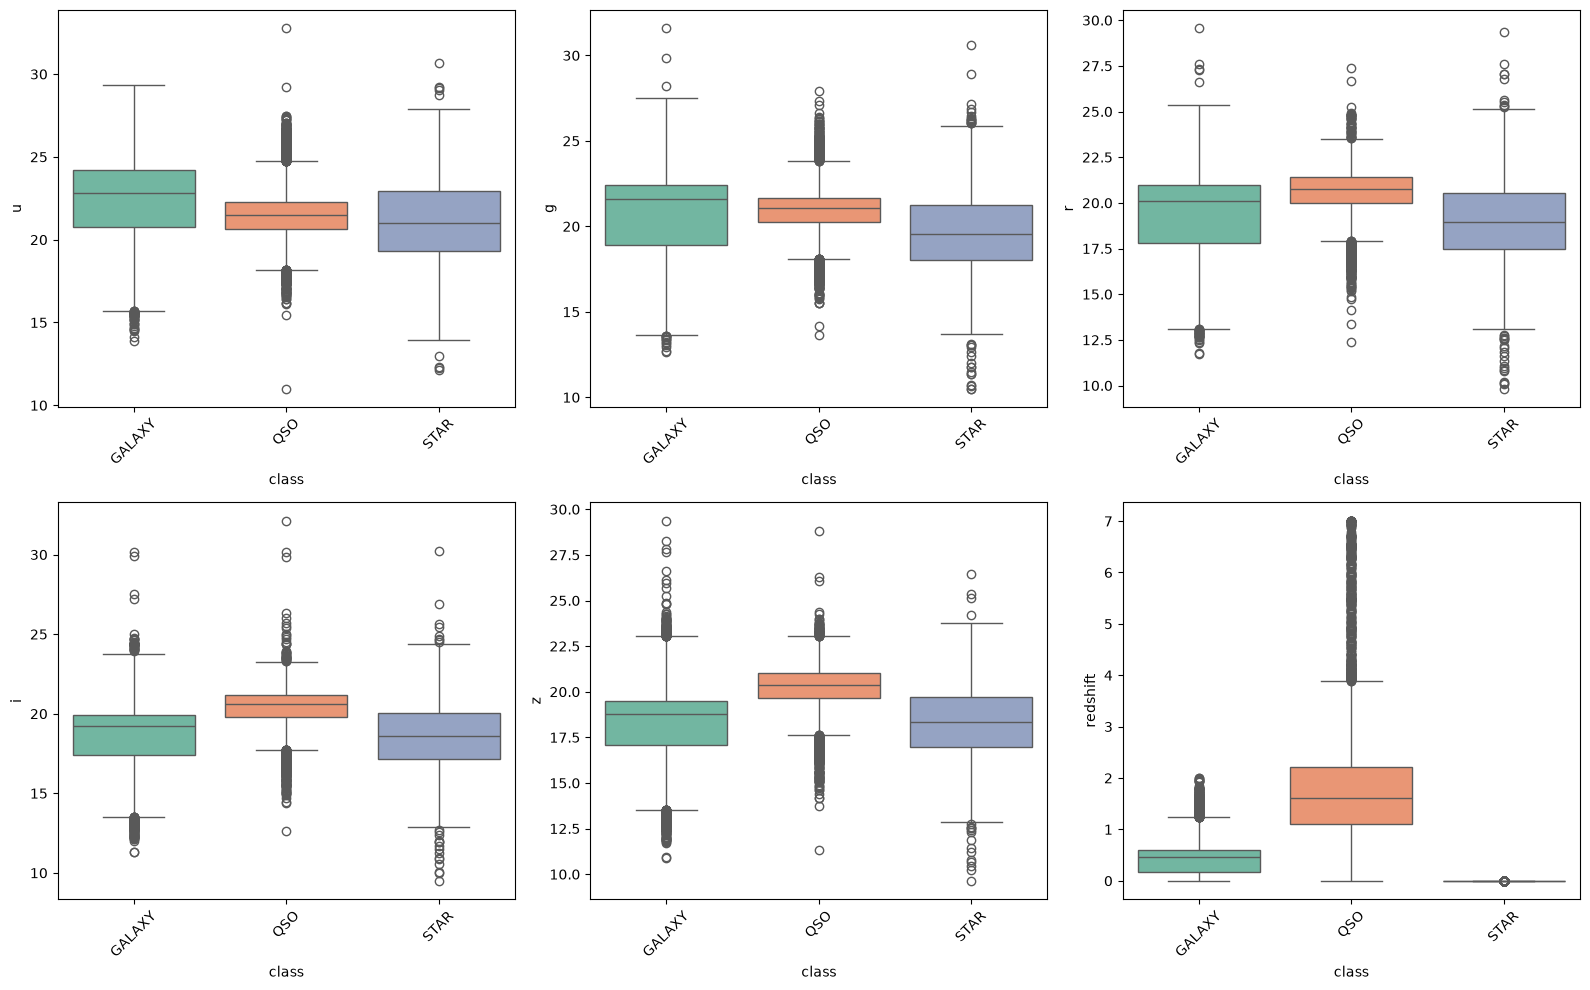

In [40]:
top_feaures = ["u", "g", "r", "i", "z", "redshift"]
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for idx, col in enumerate(top_feaures):
    # idx // 3 -> 0,1 - то есть две строки
    # idx % 3 -> 0,1,2 - то есть три столбца
    ax = axes[idx // 3][idx % 3]
    sns.boxplot(data=df, x=target_col, y=col, ax=ax, palette='Set2')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## Pairplot(key features)

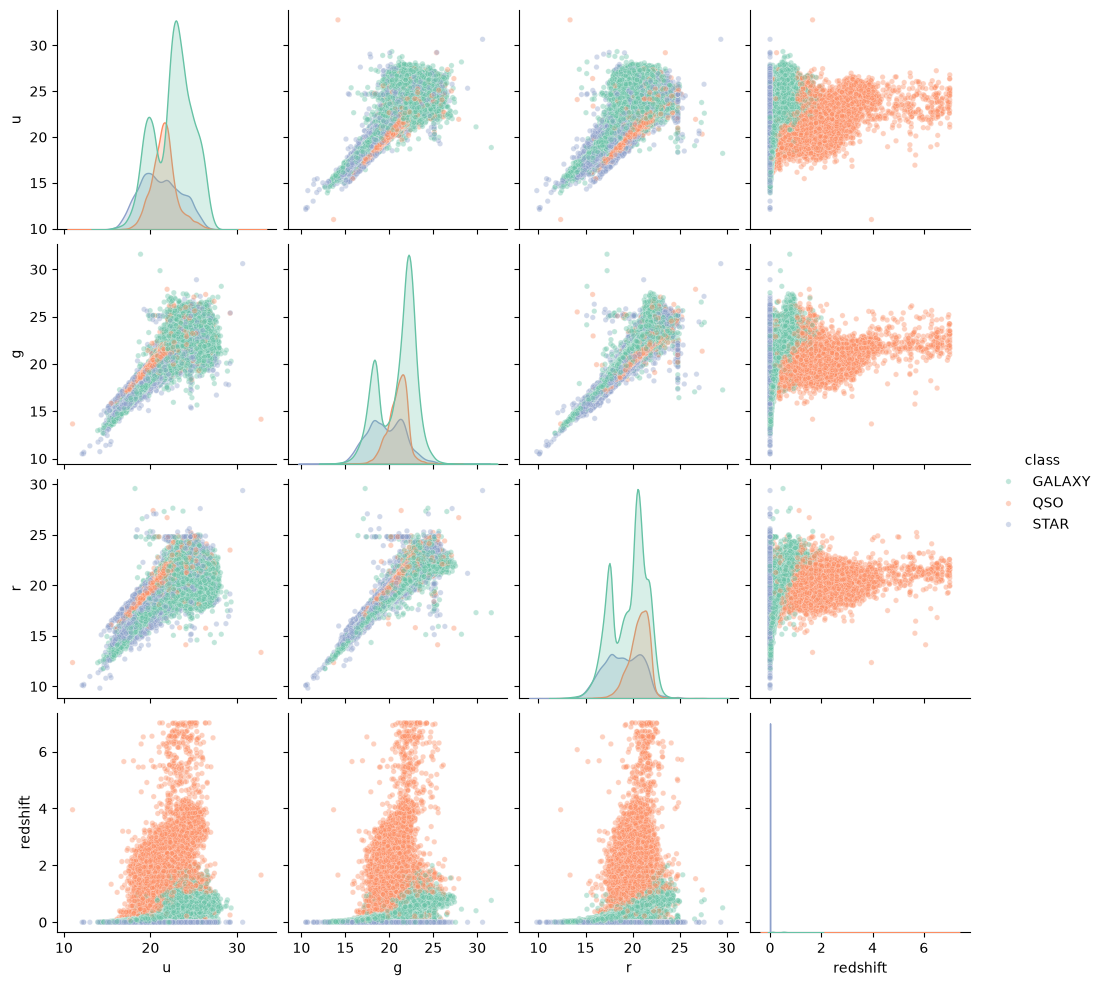

In [41]:
sns.pairplot(
    df[['u', 'g', 'r', 'redshift', target_col]],
    hue=target_col, 
    palette='Set2', 
    plot_kws={'alpha': 0.4, 's': 15}
)
plt.show()